## Delayed feedback — nonlinear external target speed

Heatmaps and speed traces for nonlinear target-speed analysis. Figures are saved to the project `figures/` directory and to `delayed_feedback_model/media/` with resolution chosen so axis labels stay clearly visible.

In [1]:
# --- Imports and path setup (paths from code/paths.py) ---
import numpy as np
import matplotlib.pyplot as plt
def inline():
    %matplotlib inline
    plt.close('all')
def widget():
    %matplotlib widget
    plt.close('all')
from scipy.interpolate import interp1d
plt.rcParams['figure.max_open_warning'] = 0
import os
import sys
from pathlib import Path
from datetime import date
_code = Path.cwd() if (Path.cwd() / "paths.py").exists() else Path.cwd().parent
if str(_code.resolve()) not in [str(Path(p).resolve()) for p in sys.path]:
    sys.path.insert(0, str(_code.resolve()))
from paths import SPEED_ONSETS_DIR, FIGURES_DIR, notebook_media_dir
path = str(SPEED_ONSETS_DIR)
path_figures = str(FIGURES_DIR)
path_media = str(notebook_media_dir("delayed_feedback_model"))

%load_ext autoreload
%autoreload 2
from functions.feedback_models import *
from tqdm import tqdm
from scipy.special import lambertw
import matplotlib as mpl
import matplotlib.colors as mcolors

OMP: Info #276: omp_set_nested routine deprecated, please use omp_set_max_active_levels instead.


In [2]:
# path, path_media set in first cell

In [3]:
# path_media created in first cell

### Example traces:

In [4]:
vts=np.logspace(np.log10(0.1),np.log10(0.5))

In [5]:
T=5
v0=1
omegaext=0.5
alpha=omegaext/0.5
tau=0.15
r=1.6
omegac=0.07
vth=0.05

tt,vs,vds,l=integrate_nonlinear_delay_equation_external_current(v0,T,omegaext,alpha,tau,r,omegac)

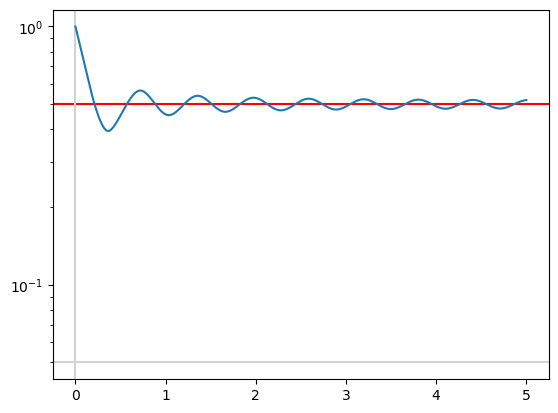

In [6]:
fig,ax=plt.subplots()
ax.axhline(omegaext/alpha,color='r')
ax.axhline(vth,color='lightgray')
ax.axvline(0,color='lightgray')
ax.plot(tt,vs)
ax.set_yscale('log')
plt.show()

In [7]:
T=20
dt=0.01

v0=2
omegaextomegac=7
rtau=0.05


tt,vs,vds,l=integrate_nonlinear_delay_equation_external_current(v0,T,omegaext=1,alpha=1,tau=1,r=rtau,omegac=1/omegaextomegac,dt=dt)

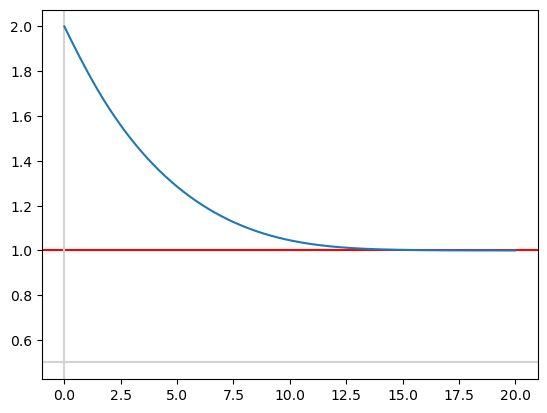

In [8]:
fig,ax=plt.subplots()
ax.axhline(1,color='r')
ax.axhline(0.5,color='lightgray')
ax.axvline(0,color='lightgray')
ax.plot(tt,vs)
plt.show()

### Phase plots with fixed values at one:

In [9]:
Npoints=100
T=50
dt=0.01
omegaextomegac=1

rtaus=np.linspace(0,2.5/omegaextomegac,Npoints)
vis=np.linspace(0,5,Npoints)
vmins_rtau=np.zeros((len(rtaus),len(vis)))
for i in tqdm(range(len(rtaus))):
    for j in range(len(vis)):
        tt,vs,vds,l=integrate_nonlinear_delay_equation_external_current(vis[j],T,omegaext=1,alpha=1,tau=1,r=rtaus[i],omegac=1/omegaextomegac,dt=dt)
        vmins_rtau[i,j]=np.min(vs)

100%|██████████| 100/100 [00:54<00:00,  1.84it/s]


In [10]:
rtaus_b=get_linear_boundaries(rtaus)
vis_b=get_linear_boundaries(vis)

In [11]:
params=[[0.2,3],[1.2,3],[2.2,3]]

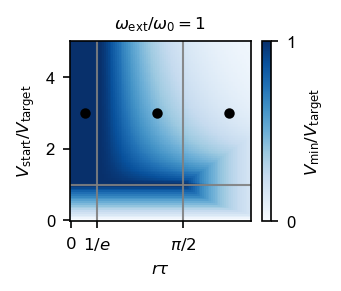

In [13]:
arial()
inline()
fig,ax=plt.subplots(figsize=np.array([1,0.8])*0.3*textwidthSI,dpi=150)
lw=1

im=ax.pcolormesh(rtaus_b,vis_b,vmins_rtau.T,cmap='Blues',vmin=0,vmax=1,rasterized=True)
cbar=fig.colorbar(im,ax=ax)
cbar.set_label(r'$V_\mathrm{min}/V_\mathrm{target}$')
cbar.set_ticks([0,1])
ax.set_xticks([0,1/np.e,np.pi/2],[r'$0$',r'$1/e$',r'$\pi/2$'])
               
clines='gray'
alphalines=0.9
lslines='-'
ax.axvline(1/np.e,color=clines,alpha=alphalines,ls=lslines,lw=lw)
ax.axvline(np.pi/2,color=clines,alpha=alphalines,ls=lslines,lw=lw)
ax.axhline(1,color=clines,alpha=alphalines,ls=lslines,lw=lw)

ax.plot([param[0] for param in params],[param[1] for param in params],'k.',ms=8)


ax.set_xlim(rtaus_b[0],rtaus_b[-1])
ax.set_ylim(vis_b[0],vis_b[-1])

ax.set_xlabel(r'$r \tau$')
ax.set_ylabel(r'$V_\mathrm{start}/V_\mathrm{target}$')
ax.set_title(r'$\omega_\mathrm{ext}/\omega_0=1$',size=8)

plt.savefig(os.path.join(path_media,f'Fig_S12a_minimum_speed_heatmap_nonlinear_rtau.pdf'),bbox_inches='tight',transparent=True,dpi=200)
plt.savefig(os.path.join(path_figures,f'Fig_S12a_minimum_speed_heatmap_nonlinear_rtau.pdf'),bbox_inches='tight',transparent=True,dpi=200)

plt.show()

In [14]:
Npoints=100
T=50
dt=0.01
rtau=1

omoms=np.linspace(0,2.5/rtau,Npoints)
vis=np.linspace(0,5,Npoints)
vmins_omom=np.zeros((len(omoms),len(vis)))
for i in tqdm(range(len(omoms))):
    for j in range(len(vis)):
        tt,vs,vds,l=integrate_nonlinear_delay_equation_external_current(vis[j],T,omegaext=1,alpha=1,tau=1,r=rtau,omegac=1/omoms[i],dt=dt)
        vmins_omom[i,j]=np.min(vs)


  0%|          | 0/100 [00:00<?, ?it/s]/var/folders/xl/ytwdm9h57dd5l_2fzzwzj7hw0000gn/T/ipykernel_15703/2406320787.py:11: RuntimeWarning: divide by zero encountered in scalar divide
  tt,vs,vds,l=integrate_nonlinear_delay_equation_external_current(vis[j],T,omegaext=1,alpha=1,tau=1,r=rtau,omegac=1/omoms[i],dt=dt)
100%|██████████| 100/100 [00:56<00:00,  1.76it/s]


In [15]:
omoms_b=get_linear_boundaries(omoms)
vis_b=get_linear_boundaries(vis)

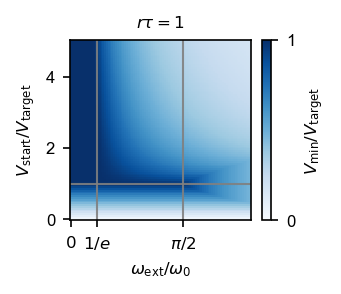

In [16]:
arial()
inline()
fig,ax=plt.subplots(figsize=np.array([1,0.8])*0.3*textwidthSI,dpi=150)
lw=1

im=ax.pcolormesh(omoms_b,vis_b,vmins_omom.T,cmap='Blues',vmin=0,vmax=1,rasterized=True)
cbar=fig.colorbar(im,ax=ax)
cbar.set_label(r'$V_\mathrm{min}/V_\mathrm{target}$')
cbar.set_ticks([0,1])
ax.set_xticks([0,1/np.e,np.pi/2],[r'$0$',r'$1/e$',r'$\pi/2$'])
               
clines='gray'
alphalines=0.9
lslines='-'
ax.axvline(1/np.e,color=clines,alpha=alphalines,ls=lslines,lw=lw)
ax.axvline(np.pi/2,color=clines,alpha=alphalines,ls=lslines,lw=lw)
ax.axhline(1,color=clines,alpha=alphalines,ls=lslines,lw=lw)


ax.set_xlim(omoms_b[0],omoms_b[-1])
ax.set_ylim(vis_b[0],vis_b[-1])

ax.set_xlabel(r'$\omega_\mathrm{ext}/\omega_0$')
ax.set_ylabel(r'$V_\mathrm{start}/V_\mathrm{target}$')
ax.set_title(r'$r \tau=1$',size=8)

plt.savefig(os.path.join(path_media,f'Fig_S12a_minimum_speed_heatmap_nonlinear_omom.pdf'),bbox_inches='tight',transparent=True,dpi=200)
plt.savefig(os.path.join(path_figures,f'Fig_S12a_minimum_speed_heatmap_nonlinear_omom.pdf'),bbox_inches='tight',transparent=True,dpi=200)

plt.show()

### Examples and phase plots with speed thresholds:

In [17]:
v_thr=0.1

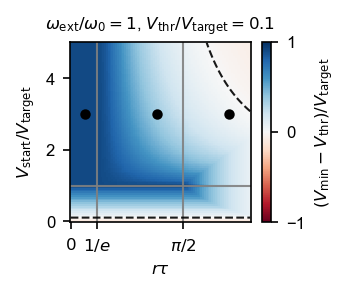

In [18]:
arial()
inline()
fig,ax=plt.subplots(figsize=np.array([1,0.8])*0.3*textwidthSI,dpi=150)
lw=1

vmins_rtau_max=np.copy(vmins_rtau)
vmins_rtau_max[vmins_rtau>1]=1

im=ax.pcolormesh(rtaus_b,vis_b,vmins_rtau_max.T-v_thr,cmap='RdBu',vmin=-1,vmax=1,rasterized=True)


cbar=fig.colorbar(im,ax=ax)
cbar.set_label(r'$(V_\mathrm{min}-V_\mathrm{thr})/V_\mathrm{target}$')
cbar.set_ticks([-1,0,1])

ax.set_xticks([0,1/np.e,np.pi/2],[r'$0$',r'$1/e$',r'$\pi/2$'])
               
clines='gray'
alphalines=0.9
lslines='-'
ax.axvline(1/np.e,color=clines,alpha=alphalines,ls=lslines,lw=lw)
ax.axvline(np.pi/2,color=clines,alpha=alphalines,ls=lslines,lw=lw)
ax.axhline(1,color=clines,alpha=alphalines,ls=lslines,lw=lw)

ax.contour(rtaus,vis,vmins_rtau.T-v_thr,0,colors='k',alpha=0.9,linestyles='dashed',linewidths=lw)

ax.plot([param[0] for param in params],[param[1] for param in params],'k.',ms=8)


ax.set_xlim(rtaus_b[0],rtaus_b[-1])
ax.set_ylim(vis_b[0],vis_b[-1])

ax.set_xlabel(r'$r \tau$')
ax.set_ylabel(r'$V_\mathrm{start}/V_\mathrm{target}$')
ax.set_title(r'$\omega_\mathrm{ext}/\omega_0=1$, $V_\mathrm{thr}/V_\mathrm{target}='+str(v_thr)+'$',size=8)

plt.savefig(os.path.join(path_media,f'Fig_S12b_minimum_speed_heatmap_nonlinear_rtau_threshold_cont_01.pdf'),bbox_inches='tight',transparent=True,dpi=200)
plt.savefig(os.path.join(path_figures,f'Fig_S12b_minimum_speed_heatmap_nonlinear_rtau_threshold_cont_01.pdf'),bbox_inches='tight',transparent=True,dpi=200)

plt.show()

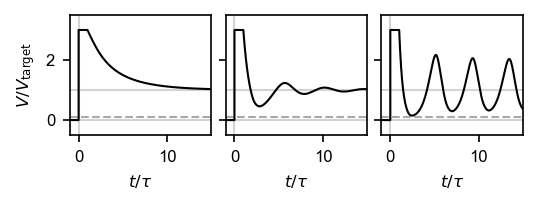

In [19]:
arial()
inline()
fig,axs=plt.subplots(1,3,figsize=np.array([1,0.8/3])*0.2*3*textwidthSI,dpi=150,sharex=True,sharey=True)
axs=axs.ravel()
plt.subplots_adjust(hspace=0.1,wspace=0.1)


T=20
dt=0.01
omegaextomegac=1

params=[[0.2,3],[1.2,3],[2.2,3]]
lw=1

for i,param in enumerate(params):
    ax=axs[i]
    rtau,vi=param

    tt,vs,vds,l=integrate_nonlinear_delay_equation_external_current(vi,T,omegaext=1,alpha=1,tau=1,r=rtau,omegac=1/omegaextomegac,dt=dt)

    vs[np.cumsum(vs<=v_thr).astype(bool)] = 0
    
    ttf=np.concatenate([[-1,0,0,1],tt+1])
    vsf=np.concatenate([[0,0,vs[0],vs[0]],vs])

    
    ax.axhline(0,color='lightgray',lw=lw)
    ax.axhline(v_thr,color='darkgray',lw=lw,ls='--')
    ax.axhline(1,color='lightgray',lw=lw)
    ax.axvline(0,color='lightgray',lw=lw)
    ax.plot(ttf,vsf,'k',lw=lw)
    ax.set_xlim(-1,15)
    ax.set_ylim(-0.5,3.5)
    ax.set_xlabel(r'$t/\tau$')

    
axs[0].set_ylabel(r'$V/V_\mathrm{target}$')



plt.savefig(os.path.join(path_media,f'Fig_S12c_example_speed_traces_nonlinear_threshold_01.pdf'),bbox_inches='tight',transparent=True,dpi=200)
plt.savefig(os.path.join(path_figures,f'Fig_S12c_example_speed_traces_nonlinear_threshold_01.pdf'),bbox_inches='tight',transparent=True,dpi=200)

plt.show()

In [20]:
v_thr=0.3

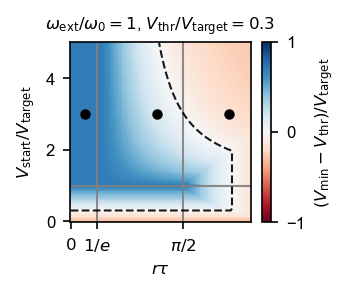

In [21]:
arial()
inline()
fig,ax=plt.subplots(figsize=np.array([1,0.8])*0.3*textwidthSI,dpi=150)
lw=1

vmins_rtau_max=np.copy(vmins_rtau)
vmins_rtau_max[vmins_rtau>1]=1

im=ax.pcolormesh(rtaus_b,vis_b,vmins_rtau_max.T-v_thr,cmap='RdBu',vmin=-1,vmax=1,rasterized=True)


cbar=fig.colorbar(im,ax=ax)
cbar.set_label(r'$(V_\mathrm{min}-V_\mathrm{thr})/V_\mathrm{target}$')
cbar.set_ticks([-1,0,1])

ax.set_xticks([0,1/np.e,np.pi/2],[r'$0$',r'$1/e$',r'$\pi/2$'])
               
clines='gray'
alphalines=0.9
lslines='-'
ax.axvline(1/np.e,color=clines,alpha=alphalines,ls=lslines,lw=lw)
ax.axvline(np.pi/2,color=clines,alpha=alphalines,ls=lslines,lw=lw)
ax.axhline(1,color=clines,alpha=alphalines,ls=lslines,lw=lw)

ax.contour(rtaus,vis,vmins_rtau.T-v_thr,0,colors='k',alpha=0.9,linestyles='dashed',linewidths=lw)

ax.plot([param[0] for param in params],[param[1] for param in params],'k.',ms=8)


ax.set_xlim(rtaus_b[0],rtaus_b[-1])
ax.set_ylim(vis_b[0],vis_b[-1])

ax.set_xlabel(r'$r \tau$')
ax.set_ylabel(r'$V_\mathrm{start}/V_\mathrm{target}$')
ax.set_title(r'$\omega_\mathrm{ext}/\omega_0=1$, $V_\mathrm{thr}/V_\mathrm{target}='+str(v_thr)+'$',size=8)

plt.savefig(os.path.join(path_media,f'Fig_S12d_minimum_speed_heatmap_nonlinear_rtau_threshold_cont_03.pdf'),bbox_inches='tight',transparent=True,dpi=200)
plt.savefig(os.path.join(path_figures,f'Fig_S12d_minimum_speed_heatmap_nonlinear_rtau_threshold_cont_03.pdf'),bbox_inches='tight',transparent=True,dpi=200)

plt.show()

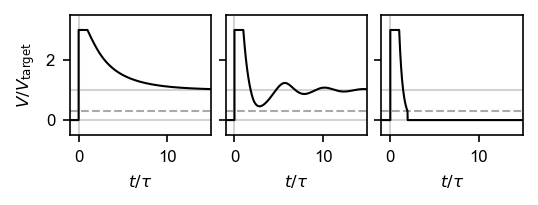

In [22]:
arial()
inline()
fig,axs=plt.subplots(1,3,figsize=np.array([1,0.8/3])*0.2*3*textwidthSI,dpi=150,sharex=True,sharey=True)
axs=axs.ravel()
plt.subplots_adjust(hspace=0.1,wspace=0.1)


T=20
dt=0.01
omegaextomegac=1

params=[[0.2,3],[1.2,3],[2.2,3]]
lw=1

for i,param in enumerate(params):
    ax=axs[i]
    rtau,vi=param

    tt,vs,vds,l=integrate_nonlinear_delay_equation_external_current(vi,T,omegaext=1,alpha=1,tau=1,r=rtau,omegac=1/omegaextomegac,dt=dt)

    vs[np.cumsum(vs<=v_thr).astype(bool)] = 0
    
    ttf=np.concatenate([[-1,0,0,1],tt+1])
    vsf=np.concatenate([[0,0,vs[0],vs[0]],vs])

    
    ax.axhline(0,color='lightgray',lw=lw)
    ax.axhline(v_thr,color='darkgray',lw=lw,ls='--')
    ax.axhline(1,color='lightgray',lw=lw)
    ax.axvline(0,color='lightgray',lw=lw)
    ax.plot(ttf,vsf,'k',lw=lw)
    ax.set_xlim(-1,15)
    ax.set_ylim(-0.5,3.5)
    ax.set_xlabel(r'$t/\tau$')

    
axs[0].set_ylabel(r'$V/V_\mathrm{target}$')



plt.savefig(os.path.join(path_media,f'Fig_S12e_example_speed_traces_nonlinear_threshold_03.pdf'),bbox_inches='tight',transparent=True,dpi=200)
plt.savefig(os.path.join(path_figures,f'Fig_S12e_example_speed_traces_nonlinear_threshold_03.pdf'),bbox_inches='tight',transparent=True,dpi=200)

plt.show()

In [23]:
v_thr=0.6

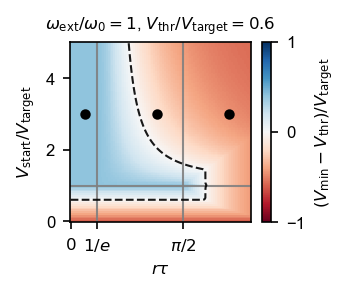

In [24]:
arial()
inline()
fig,ax=plt.subplots(figsize=np.array([1,0.8])*0.3*textwidthSI,dpi=150)
lw=1

vmins_rtau_max=np.copy(vmins_rtau)
vmins_rtau_max[vmins_rtau>1]=1

im=ax.pcolormesh(rtaus_b,vis_b,vmins_rtau_max.T-v_thr,cmap='RdBu',vmin=-1,vmax=1,rasterized=True)


cbar=fig.colorbar(im,ax=ax)
cbar.set_label(r'$(V_\mathrm{min}-V_\mathrm{thr})/V_\mathrm{target}$')
cbar.set_ticks([-1,0,1])

ax.set_xticks([0,1/np.e,np.pi/2],[r'$0$',r'$1/e$',r'$\pi/2$'])
               
clines='gray'
alphalines=0.9
lslines='-'
ax.axvline(1/np.e,color=clines,alpha=alphalines,ls=lslines,lw=lw)
ax.axvline(np.pi/2,color=clines,alpha=alphalines,ls=lslines,lw=lw)
ax.axhline(1,color=clines,alpha=alphalines,ls=lslines,lw=lw)

ax.contour(rtaus,vis,vmins_rtau.T-v_thr,0,colors='k',alpha=0.9,linestyles='dashed',linewidths=lw)

ax.plot([param[0] for param in params],[param[1] for param in params],'k.',ms=8)


ax.set_xlim(rtaus_b[0],rtaus_b[-1])
ax.set_ylim(vis_b[0],vis_b[-1])

ax.set_xlabel(r'$r \tau$')
ax.set_ylabel(r'$V_\mathrm{start}/V_\mathrm{target}$')
ax.set_title(r'$\omega_\mathrm{ext}/\omega_0=1$, $V_\mathrm{thr}/V_\mathrm{target}='+str(v_thr)+'$',size=8)

plt.savefig(os.path.join(path_media,f'Fig_S12f_minimum_speed_heatmap_nonlinear_rtau_threshold_cont_06.pdf'),bbox_inches='tight',transparent=True,dpi=200)
plt.savefig(os.path.join(path_figures,f'Fig_S12f_minimum_speed_heatmap_nonlinear_rtau_threshold_cont_06.pdf'),bbox_inches='tight',transparent=True,dpi=200)

plt.show()

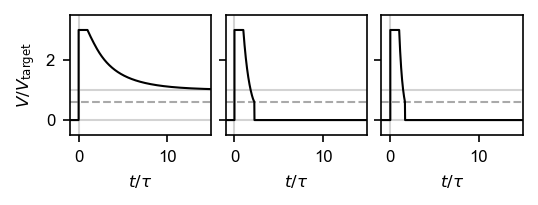

In [25]:
arial()
inline()
fig,axs=plt.subplots(1,3,figsize=np.array([1,0.8/3])*0.2*3*textwidthSI,dpi=150,sharex=True,sharey=True)
axs=axs.ravel()
plt.subplots_adjust(hspace=0.1,wspace=0.1)


T=20
dt=0.01
omegaextomegac=1

params=[[0.2,3],[1.2,3],[2.2,3]]
lw=1

for i,param in enumerate(params):
    ax=axs[i]
    rtau,vi=param

    tt,vs,vds,l=integrate_nonlinear_delay_equation_external_current(vi,T,omegaext=1,alpha=1,tau=1,r=rtau,omegac=1/omegaextomegac,dt=dt)

    vs[np.cumsum(vs<=v_thr).astype(bool)] = 0
    
    ttf=np.concatenate([[-1,0,0,1],tt+1])
    vsf=np.concatenate([[0,0,vs[0],vs[0]],vs])

    
    ax.axhline(0,color='lightgray',lw=lw)
    ax.axhline(v_thr,color='darkgray',lw=lw,ls='--')
    ax.axhline(1,color='lightgray',lw=lw)
    ax.axvline(0,color='lightgray',lw=lw)
    ax.plot(ttf,vsf,'k',lw=lw)
    ax.set_xlim(-1,15)
    ax.set_ylim(-0.5,3.5)
    ax.set_xlabel(r'$t/\tau$')

    
axs[0].set_ylabel(r'$V/V_\mathrm{target}$')


plt.savefig(os.path.join(path_media,f'Fig_S12g_example_speed_traces_nonlinear_threshold_06.pdf'),bbox_inches='tight',transparent=True,dpi=200)
plt.savefig(os.path.join(path_figures,f'Fig_S12g_example_speed_traces_nonlinear_threshold_06.pdf'),bbox_inches='tight',transparent=True,dpi=200)

plt.show()